# Riesgo sísmico en Santander — Notebook auditado y mejorado

**Qué es este documento:** una versión corregida del notebook `hackathonUTS.ipynb`. Explica, en palabras sencillas, qué estaba mal en la versión original, cómo se arregló y qué resultados da el modelo con **tus datos reales** (los Excel del SGC en `datos/raw/`).

**Regla de oro de esta versión:** ningún dato se inventa, se simula ni se rellena artificialmente. Todo número que verás sale de los archivos Excel de `datos/raw/`. Si algo falta en tus datos, el notebook lo dice en voz alta en lugar de taparlo.

> ⚠️ **Nota de honestidad:** el código descubre las columnas reales de los Excel de `datos/raw/` y reporta lo que encuentra, sin inventar datos. Los resultados (métricas, gráficas) aparecerán cuando lo ejecutes en tu equipo.

## Parte 1 · Diagnóstico del notebook original

Esto es lo que se encontró al revisar el notebook original (los números vienen de las salidas que quedaron guardadas en él).

| # | Hallazgo | Por qué importa | Gravedad |
|---|---|---|---|
| 1 | **El modelo "hace trampa" (fuga de información).** La etiqueta de riesgo se calcula *a partir de* `Magnitud` y `Profundidad`, y esas mismas dos columnas se le dan al modelo como pistas. | Es como un examen donde la respuesta está escrita en la pregunta. El modelo no aprende nada sobre sismos: solo redescubre la regla que nosotros le escribimos. El "1.00" de exactitud no significa que sea bueno. | 🔴 Crítica |
| 2 | **La clase "Alto" casi no existe.** De 103 810 registros, solo **3** quedaron como riesgo Alto (0,003 %). En la prueba hubo **0**. | Con 3 ejemplos no se puede entrenar ni evaluar nada. El reporte muestra 0.00 para "Alto" y eso se ignoró. | 🔴 Crítica |
| 3 | **SMOTE fabricó ~154 000 filas sintéticas.** Pasó de 83 048 a 237 306 registros de entrenamiento, de los cuales unos 154 258 son inventados (a partir de apenas 3 sismos reales "Altos"). | Va en contra de la regla de no simular datos. Además, un modelo entrenado con datos inventados no refleja la realidad. | 🔴 Crítica |
| 4 | **Filas duplicadas.** La tabla de salida muestra pares de sismos idénticos (misma magnitud, profundidad y coordenadas, con índices separados por ~43 500 filas), señal de que los archivos se solapan. | Los duplicados cuentan dos veces el mismo sismo, inflan los totales y pueden caer uno en entrenamiento y otro en prueba (otra forma de trampa). | 🟠 Alta |
| 5 | **Municipios inventados.** Si no se encontraba la región, el código asignaba "Los Santos" por defecto, o repartía "Zapatoca / Jordán / Betulia" con cortes de latitud puestos a mano. | Es información fabricada que se presenta como real. | 🔴 Crítica |
| 6 | **Solo 6 variables, no 20.** Se usan `Latitud, Longitud, Magnitud, Profundidad, RMS, Gap`. Las demás columnas del catálogo (errores, número de estaciones, fecha…) se descartan. | No cumple el requisito de 20 variables bien definidas y pierde información útil. | 🟠 Alta |
| 7 | **Se borraban sismos reales por tener `RMS` o `Gap` vacíos** (`dropna` sobre 6 columnas). | Se pierden eventos válidos solo porque falta un dato de calidad. | 🟡 Media |
| 8 | **División aleatoria 80/20 en datos que dependen del tiempo.** | Mezcla pasado y futuro: el modelo "ve" sismos vecinos en el tiempo durante el entrenamiento. Para predecir el futuro hay que probar con un futuro real. | 🟠 Alta |
| 9 | **Los textos de riesgo no coinciden con la zona.** Santander tiene el famoso *Nido Sísmico de Bucaramanga*, donde los sismos son profundos (~150 km). La regla "Alto = profundidad < 30 km" casi nunca se cumple. | Se le promete al usuario una alerta que el modelo prácticamente nunca puede dar. | 🟠 Alta |
| 10 | **La interfaz usaba valores de ejemplo escritos a mano** (lat 6.802, prof. 140…). | Son valores sin origen en tus datos. | 🟡 Media |
| 11 | **Orden de ejecución desordenado y dependencias ocultas** (el análisis final usa `df_unido` de otra celda; los contadores de ejecución muestran celdas corridas fuera de orden). | El notebook falla o da distinto si se corre de arriba abajo. | 🟡 Media |

**Lo que sí estaba bien:** buscar automáticamente la fila de encabezados en los Excel, usar el motor `calamine` para leer archivos con formato raro, y la idea de dar una vista simple para el público.

## Parte 2 · El nuevo enfoque (explicado para cualquiera)

**Pregunta que responde el modelo:**
> *Mirando lo que pasó en la última semana (y las 3 anteriores), ¿es probable que la semana siguiente tenga un sismo fuerte?*

**¿Por qué así?** Predecir *cuándo* ocurre un sismo individual es imposible hoy en día. Lo que sí se puede hacer, con honestidad, es medir si la actividad reciente está más agitada de lo normal y qué tan bien esa señal anticipa semanas de actividad alta.

**Cómo se evita la trampa de antes:**
1. Las variables describen **la semana que ya pasó**. El objetivo es **la semana siguiente**. Nunca se mezclan.
2. El umbral de "fuerte" se calcula **solo con datos de entrenamiento**.
3. Se entrena con el pasado y se prueba con el **futuro** (el último 20 % cronológico).
4. No se crean datos sintéticos. El desbalance se maneja dándole más peso a la clase poco frecuente.
5. El modelo se compara contra métodos simples. Si no los supera, se dice.

**¿Qué es un "sismo fuerte" aquí?** La semana siguiente se marca como **actividad alta** si su sismo de mayor magnitud supera un umbral. Por defecto es el **percentil 75** de las semanas de entrenamiento (es decir, el 25 % de semanas más intensas), y puede cambiarse por una magnitud fija en la celda de configuración.

## Parte 3 · Configuración

Aquí están **todos los ajustes** en un solo lugar. Si quieres otra ruta, otra ventana de tiempo o un umbral fijo, es lo único que debes cambiar.

In [1]:
import glob, os, re, unicodedata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Motor para leer Excel con formatos raros (si no está instalado, descomenta la línea siguiente)
# %pip install python-calamine

# ------------------------- CONFIGURACIÓN -------------------------
# Busca la raíz del repo (sube carpetas hasta hallar "datos") y usa los .xlsx reales del SGC.
from pathlib import Path
RAIZ = Path.cwd()
while not (RAIZ / "datos").exists() and RAIZ.parent != RAIZ:
    RAIZ = RAIZ.parent
RUTA_CARPETA = str(RAIZ / "datos" / "raw")   # aquí están los .xlsx del SGC
VENTANA             = "7D"            # tamaño de la ventana de tiempo (7D = una semana)
MAG_FUERTE          = 3.5             # magnitud a partir de la cual un sismo cuenta como "fuerte" (conteo)
UMBRAL_PERCENTIL    = 0.75            # "actividad alta" = semana siguiente en el 25 % más intenso (solo entrenamiento)
UMBRAL_MAG_FIJO     = None            # ej. 4.0 para usar una magnitud fija en vez del percentil
PROPORCION_TRAIN    = 0.80            # primer 80 % cronológico = entrenamiento, 20 % final = prueba
FECHA_DIA_PRIMERO   = False           # True si tus fechas vienen como dd/mm/aaaa
SEMILLA             = 42
# ------------------------------------------------------------------
sns.set_theme(style="whitegrid")
print("Configuración cargada.")

Configuración cargada.


## Parte 4 · Carga de los datos reales

**Qué hace:** abre cada archivo Excel de `datos/raw/`, busca la fila donde empiezan los encabezados reales (algunos archivos traen títulos arriba), unifica los nombres de columnas y junta todo en una sola tabla.

**Qué cambió respecto al original:**
- Se conservan **todas** las columnas útiles (antes se tiraban casi todas).
- Se anota de qué archivo viene cada fila.
- Los nombres se normalizan sin tildes (así "PROFUNDIDAD", "Profundidad" y "PROFUNDIDÁD" se reconocen igual).
- Se informa cuántas filas aporta cada archivo.

In [2]:
def normalizar(txt):
    # Mayúsculas, sin tildes y sin espacios repetidos
    txt = unicodedata.normalize("NFKD", str(txt)).encode("ascii", "ignore").decode().upper().strip()
    return re.sub(r"\s+", " ", txt)

INDICADORES = ["FECHA", "LATITUD", "LONGITUD", "PROFUNDIDAD", "MAGNITUD"]

def nombre_estandar(col):
    # Traduce el nombre original de una columna a un nombre estándar. Devuelve None si no nos interesa.
    es_error = "ERROR" in col
    if "FECHA" in col:                      return "Fecha"
    if "LATITUD" in col:                    return "Error_Latitud" if es_error else "Latitud"
    if "LONGITUD" in col:                   return "Error_Longitud" if es_error else "Longitud"
    if "PROF" in col:                       return "Error_Profundidad" if es_error else "Profundidad"
    if "MAGNITUD" in col:
        if "TIPO" in col:                   return "Tipo_Magnitud"
        return "Error_Magnitud" if es_error else "Magnitud"
    if es_error:                            return None
    if "RMS" in col:                        return "RMS"
    if "GAP" in col:                        return "Gap"
    if "ESTACION" in col or "NUM_EST" in col: return "Num_Estaciones"
    if "REGION" in col:                     return "Region"
    return None

def leer_archivo(ruta):
    crudo = pd.read_excel(ruta, engine="calamine", header=None)
    fila_enc = None
    for i in range(min(20, len(crudo))):
        valores = [normalizar(v) for v in crudo.iloc[i].values]
        aciertos = sum(any(ind in v for v in valores) for ind in INDICADORES)
        if aciertos >= 3:
            fila_enc = i
            break
    if fila_enc is None:
        raise ValueError("no se encontró una fila de encabezados con FECHA/LATITUD/LONGITUD/PROFUNDIDAD/MAGNITUD")
    nombres = [normalizar(v) for v in crudo.iloc[fila_enc].values]
    datos = crudo.iloc[fila_enc + 1:].reset_index(drop=True)
    datos.columns = nombres
    # Quedarse con la PRIMERA columna que corresponda a cada nombre estándar
    elegidas = {}
    for col in datos.columns:
        std = nombre_estandar(col)
        if std is not None and std not in elegidas:
            elegidas[std] = datos[col]
    salida = pd.DataFrame(elegidas)
    salida["Archivo"] = os.path.basename(ruta)
    return salida

# Se excluye "datos_sismicos_santander.xlsx": es la unificación del compañero y duplicaría filas.
archivos = [a for a in sorted(glob.glob(os.path.join(RUTA_CARPETA, "*.xlsx"))) if "datos_sismicos" not in os.path.basename(a)]
if not archivos:
    raise FileNotFoundError(f"No se encontraron .xlsx en '{RUTA_CARPETA}'. Revisa RUTA_CARPETA.")

partes, resumen_archivos = [], []
for ruta in archivos:
    try:
        p = leer_archivo(ruta)
        partes.append(p)
        resumen_archivos.append({"Archivo": os.path.basename(ruta), "Filas leídas": len(p), "Columnas reconocidas": ", ".join(c for c in p.columns if c != "Archivo")})
    except Exception as e:
        resumen_archivos.append({"Archivo": os.path.basename(ruta), "Filas leídas": 0, "Columnas reconocidas": f"ERROR: {e}"})

print(pd.DataFrame(resumen_archivos).to_string(index=False))
df_crudo = pd.concat(partes, ignore_index=True)
print(f"\nTotal de filas leídas (sin limpiar): {len(df_crudo):,}")

         Archivo  Filas leídas                                                                                                               Columnas reconocidas
  2021-2023.xlsx         34795 Fecha, Latitud, Longitud, Profundidad, Magnitud, Tipo_Magnitud, RMS, Gap, Error_Latitud, Error_Longitud, Error_Profundidad, Region
reporte1336.xlsx         32678 Fecha, Latitud, Longitud, Profundidad, Magnitud, Tipo_Magnitud, RMS, Gap, Error_Latitud, Error_Longitud, Error_Profundidad, Region
reporte1476.xlsx         29614                        Fecha, Latitud, Longitud, Profundidad, Magnitud, RMS, Gap, Error_Latitud, Error_Longitud, Error_Profundidad
reporte1668.xlsx         30696                        Fecha, Latitud, Longitud, Profundidad, Magnitud, RMS, Gap, Error_Latitud, Error_Longitud, Error_Profundidad
reporte1893.xlsx         12892                        Fecha, Latitud, Longitud, Profundidad, Magnitud, RMS, Gap, Error_Latitud, Error_Longitud, Error_Profundidad
reporte1977.xlsx         306

### ¿Están las columnas esenciales?
Un sismo sin fecha, ubicación, profundidad o magnitud no sirve. Esta celda verifica que existan; si no, se detiene y te muestra qué encontró, en vez de seguir con datos incompletos.

In [3]:
ESENCIALES = ["Fecha", "Latitud", "Longitud", "Profundidad", "Magnitud"]
faltan = [c for c in ESENCIALES if c not in df_crudo.columns]
if faltan:
    raise KeyError(f"Faltan columnas esenciales: {faltan}. Columnas encontradas: {list(df_crudo.columns)}")

OPCIONALES = ["RMS", "Gap", "Num_Estaciones", "Error_Latitud", "Error_Longitud", "Error_Profundidad", "Error_Magnitud", "Tipo_Magnitud", "Region"]
print("Columnas esenciales: OK")
print("Opcionales encontradas :", [c for c in OPCIONALES if c in df_crudo.columns])
print("Opcionales NO encontradas:", [c for c in OPCIONALES if c not in df_crudo.columns])

Columnas esenciales: OK
Opcionales encontradas : ['RMS', 'Gap', 'Error_Latitud', 'Error_Longitud', 'Error_Profundidad', 'Tipo_Magnitud', 'Region']
Opcionales NO encontradas: ['Num_Estaciones', 'Error_Magnitud']


## Parte 5 · Limpieza paso a paso (con cuentas claras)

**Qué hace y por qué:**

1. **Convierte tipos.** Todo lo que debe ser número se convierte a número; la fecha, a fecha. Lo que no se pueda convertir queda vacío (no se inventa nada).
2. **Quita filas sin dato esencial.** Pero **ya no** se borran sismos por tener `RMS` o `Gap` vacíos (eran datos de calidad, no esenciales).
3. **Valida rangos físicos.** Latitud entre −90 y 90, longitud entre −180 y 180, profundidad ≥ 0 y magnitud entre −2 y 10. Fuera de eso es un error de captura.
4. **Elimina duplicados exactos.** Un mismo sismo repetido (misma fecha, coordenadas, profundidad y magnitud) cuenta una sola vez.

Al final verás una tabla que dice cuántas filas se quitaron en cada paso.

In [4]:
df = df_crudo.copy()

# 1) Tipos
cols_num = [c for c in ["Latitud","Longitud","Profundidad","Magnitud","RMS","Gap","Num_Estaciones",
                        "Error_Latitud","Error_Longitud","Error_Profundidad","Error_Magnitud"] if c in df.columns]
for c in cols_num:
    df[c] = pd.to_numeric(df[c], errors="coerce")
# format="mixed": acepta fechas con hora (formato nuevo) y sin hora (formato viejo) en la misma columna.
df["Fecha"] = pd.to_datetime(df["Fecha"], errors="coerce", dayfirst=FECHA_DIA_PRIMERO, format="mixed")

pct_fecha = df["Fecha"].notna().mean() * 100
print(f"Fechas interpretadas correctamente: {pct_fecha:.1f} %")
if pct_fecha < 90:
    print("⚠️  Menos del 90 % de las fechas se interpretó. Revisa el formato (¿dd/mm/aaaa? prueba FECHA_DIA_PRIMERO=True).")
    print(df_crudo["Fecha"].dropna().head(5).tolist())

bitacora = [("Filas leídas", len(df))]

# 2) Sin dato esencial
df = df.dropna(subset=ESENCIALES)
bitacora.append(("Después de quitar filas sin fecha/lat/lon/prof/mag", len(df)))

# 3) Rangos físicos
rango_ok = (df["Latitud"].between(-90, 90) & df["Longitud"].between(-180, 180) &
            (df["Profundidad"] >= 0) & df["Magnitud"].between(-2, 10))
df = df[rango_ok]
bitacora.append(("Después de validar rangos físicos", len(df)))

# 4) Duplicados exactos
claves = ["Fecha", "Latitud", "Longitud", "Profundidad", "Magnitud"]
n_antes = len(df)
df = df.drop_duplicates(subset=claves).sort_values("Fecha").reset_index(drop=True)
bitacora.append(("Después de eliminar duplicados exactos", len(df)))

tabla_limpieza = pd.DataFrame(bitacora, columns=["Paso", "Filas restantes"])
tabla_limpieza["Filas quitadas en el paso"] = (-tabla_limpieza["Filas restantes"].diff()).fillna(0).astype(int)
print(tabla_limpieza.to_string(index=False))
print(f"\nDuplicados eliminados: {n_antes - len(df):,}  |  Periodo cubierto: {df['Fecha'].min().date()} → {df['Fecha'].max().date()}")

df.to_csv(RAIZ / "modelos/supervisado/datos_sismicos_santander_limpio.csv", index=False)
print("Guardado: datos_sismicos_santander_limpio.csv")

Fechas interpretadas correctamente: 100.0 %
                                              Paso  Filas restantes  Filas quitadas en el paso
                                      Filas leídas           205916                          0
Después de quitar filas sin fecha/lat/lon/prof/mag           205916                          0
                 Después de validar rangos físicos           205787                        129
            Después de eliminar duplicados exactos           175056                      30731

Duplicados eliminados: 30,731  |  Periodo cubierto: 1993-06-01 → 2026-10-13


Guardado: datos_sismicos_santander_limpio.csv


### Chequeo de datos vacíos
Esta tabla muestra qué porcentaje de cada columna está vacío. **No se rellena nada con datos inventados.** Los vacíos se manejan más adelante de forma estándar y transparente (ver Parte 8).

In [5]:
vacios = (df.drop(columns=["Archivo"]).isna().mean() * 100).round(2).rename("% vacío").to_frame()
vacios["Registros con dato"] = df.drop(columns=["Archivo"]).notna().sum()
display(vacios.sort_values("% vacío", ascending=False))

,% vacío,Registros con dato
Region,41.80,101888
Tipo_Magnitud,41.80,101888
RMS,0.05,174968
Gap,0.05,174968
Error_Longitud,0.05,174968
Error_Latitud,0.05,174968
Error_Profundidad,0.05,174968
Fecha,0.00,175056
Profundidad,0.00,175056
Longitud,0.00,175056


## Parte 6 · Conociendo los datos (análisis exploratorio)

**Para qué sirve:** antes de modelar hay que *mirar* los datos. Estas gráficas responden a preguntas básicas: ¿cuántos sismos hay por año?, ¿qué tan fuertes?, ¿qué tan profundos?, ¿dónde ocurren?

**Cómo leerlas:**
- *Sismos por año:* si un año tiene muchos más que otros, puede ser actividad real **o** un cambio en la red de sensores. Hay que tenerlo en cuenta.
- *Magnitud:* casi siempre hay muchísimos sismos pequeños y muy pocos grandes (la escala del eje vertical es logarítmica para poder verlos).
- *Profundidad y mapa:* en Santander se espera una concentración de sismos muy profundos en un punto (el nido de Bucaramanga).

,count,mean,std,min,25%,50%,75%,max
Latitud,175056.0,6.772,0.218,5.711,6.759,6.794,6.825,8.103
Longitud,175056.0,-73.195,0.207,-74.491,-73.196,-73.151,-73.100,-72.403
Profundidad,175056.0,136.661,23.864,0.000,135.400,142.800,147.700,224.400
Magnitud,175056.0,2.037,0.599,0.000,1.600,1.900,2.300,6.200
RMS,174968.0,0.511,0.292,0.000,0.300,0.400,0.700,9.400
Gap,174968.0,154.071,61.278,0.000,113.000,142.000,191.000,349.000


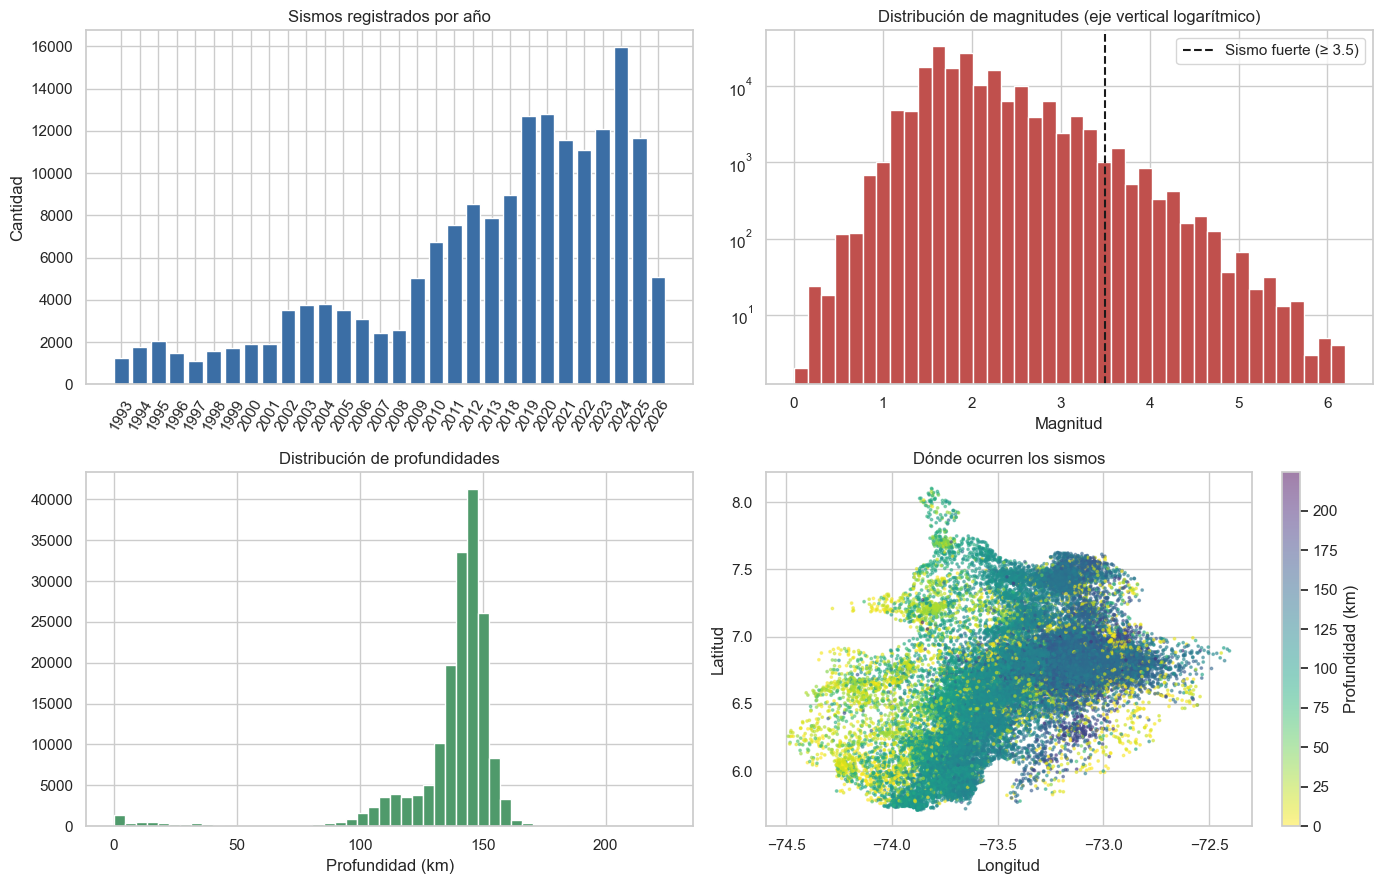

In [6]:
resumen = df[["Latitud","Longitud","Profundidad","Magnitud"] + [c for c in ["RMS","Gap","Num_Estaciones"] if c in df.columns]].describe().T
display(resumen.round(3))

fig, ax = plt.subplots(2, 2, figsize=(14, 9))

por_anio = df["Fecha"].dt.year.value_counts().sort_index()
ax[0,0].bar(por_anio.index.astype(str), por_anio.values, color="#3b6ea5")
ax[0,0].set_title("Sismos registrados por año"); ax[0,0].set_ylabel("Cantidad"); ax[0,0].tick_params(axis="x", rotation=60)

ax[0,1].hist(df["Magnitud"], bins=40, color="#c0504d"); ax[0,1].set_yscale("log")
ax[0,1].axvline(MAG_FUERTE, color="k", ls="--", label=f"Sismo fuerte (≥ {MAG_FUERTE})"); ax[0,1].legend()
ax[0,1].set_title("Distribución de magnitudes (eje vertical logarítmico)"); ax[0,1].set_xlabel("Magnitud")

ax[1,0].hist(df["Profundidad"], bins=50, color="#4f9a6b")
ax[1,0].set_title("Distribución de profundidades"); ax[1,0].set_xlabel("Profundidad (km)")

sc = ax[1,1].scatter(df["Longitud"], df["Latitud"], c=df["Profundidad"], s=3, cmap="viridis_r", alpha=0.5)
plt.colorbar(sc, ax=ax[1,1], label="Profundidad (km)")
ax[1,1].set_title("Dónde ocurren los sismos"); ax[1,1].set_xlabel("Longitud"); ax[1,1].set_ylabel("Latitud")
plt.tight_layout(); plt.show()

### ¿Qué zonas aparecen en el catálogo?
Si tus archivos traen la columna `REGION`, aquí se cuentan los sismos por la zona **tal como viene escrita en el archivo** (se toma el texto antes del primer guion). No se asigna ningún municipio por cálculo propio ni por defecto; los registros sin región se reportan como "Sin dato".

,Sismos
Region,
Sin dato,73168
Los Santos,56552
Zapatoca,13643
Villanueva,4681
El Carmen,2488
San Vicente de Chucurí,2003
Jordán,1763
Rionegro,1630
Barichara,1423


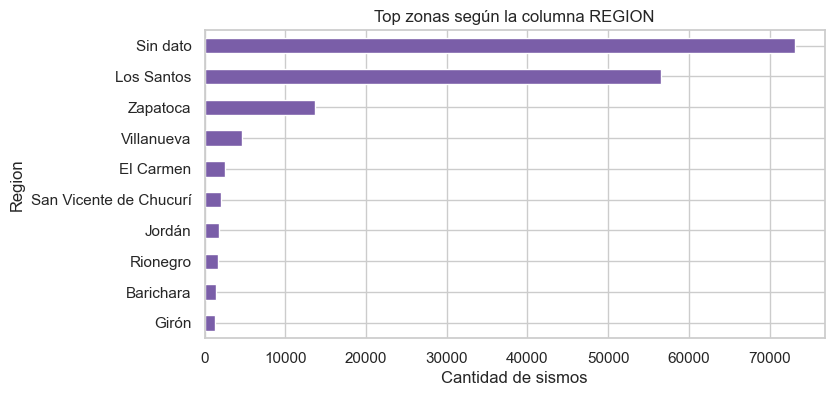

In [7]:
if "Region" in df.columns and df["Region"].notna().any():
    zona = df["Region"].astype("string").str.split("-").str[0].str.strip()
    conteo = zona.fillna("Sin dato").value_counts()
    display(conteo.head(10).rename("Sismos").to_frame())
    conteo.head(10).sort_values().plot(kind="barh", color="#7a5ea8", figsize=(8, 4), title="Top zonas según la columna REGION")
    plt.xlabel("Cantidad de sismos"); plt.show()
else:
    print("Los archivos no traen columna REGION: se omite este análisis (no se inventan municipios).")

## Parte 7 · Las 20 variables (explicadas una por una)

**Idea central:** en vez de mirar cada sismo suelto, resumimos cada **semana** de actividad con números. Cada fila de la tabla nueva = una semana; cada columna = una variable que describe qué pasó en esa semana.

**Todas se calculan con tus datos reales** (conteos, promedios, máximos). Ninguna es inventada. Hay tres familias:

- **A. Intensidad** (qué tan fuertes y cuántos): número de sismos, magnitud media/máxima/dispersión, sismos fuertes, energía liberada.
- **B. Ubicación y profundidad** (dónde): profundidad media/mínima/dispersión, latitud y longitud medias.
- **C. Calidad de la medición** (qué tan confiable es el dato): RMS, Gap, número de estaciones y errores de localización.
- **D. Memoria reciente** (contexto): promedio de sismos de las últimas 4 semanas, magnitud máxima de las últimas 4 semanas y cuántas semanas pasaron desde el último sismo fuerte.

**Sobre la energía:** se usa la fórmula estándar de Gutenberg–Richter, `E = 10^(1,5·M + 4,8)` julios. Cada punto de magnitud multiplica la energía unas 31 veces; por eso se suma energía (no magnitudes) y se muestra en escala logarítmica.

**Si a tus archivos les falta alguna columna** (por ejemplo, no traen número de estaciones), esa variable simplemente no se crea y el notebook te avisa cuántas quedaron. No se rellena con valores inventados.

In [8]:
d = df.copy()
d["Energia_J"] = 10 ** (1.5 * d["Magnitud"] + 4.8)       # Gutenberg-Richter
d["Es_fuerte"] = (d["Magnitud"] >= MAG_FUERTE).astype(int)

g = d.groupby(pd.Grouper(key="Fecha", freq=VENTANA))
agg = pd.DataFrame(index=g.size().index)

# Catálogo: (nombre, familia, qué mide, cómo se calcula, columna real de origen)
catalogo = []
def registrar(nombre, familia, mide, calculo, origen):
    catalogo.append({"Variable": nombre, "Familia": familia, "Qué mide": mide, "Cómo se calcula": calculo, "Columna de origen": origen})

# --- A. Intensidad
agg["n_eventos"] = g.size()
registrar("n_eventos", "A. Intensidad", "Cuántos sismos hubo en la ventana", "Conteo de registros", "Fecha")

agg["mag_media"] = g["Magnitud"].mean()
registrar("mag_media", "A. Intensidad", "Magnitud típica de la ventana", "Promedio de Magnitud", "Magnitud")
agg["mag_max"] = g["Magnitud"].max()
registrar("mag_max", "A. Intensidad", "El sismo más fuerte de la ventana", "Máximo de Magnitud", "Magnitud")
agg["mag_desv"] = g["Magnitud"].std()
registrar("mag_desv", "A. Intensidad", "Qué tan dispares fueron las magnitudes", "Desviación estándar de Magnitud", "Magnitud")

agg["n_fuertes"] = g["Es_fuerte"].sum()
registrar("n_fuertes", "A. Intensidad", f"Cuántos sismos con magnitud ≥ {MAG_FUERTE}", "Conteo de sismos sobre MAG_FUERTE", "Magnitud")

energia = g["Energia_J"].sum()
agg["energia_log10"] = np.log10(energia.where(energia > 0))
registrar("energia_log10", "A. Intensidad", "Energía total liberada (escala log)", "log10(Σ 10^(1,5·M+4,8))", "Magnitud")

# --- B. Ubicación y profundidad
for nombre, col, fn, mide, calc in [
    ("prof_media", "Profundidad", "mean", "Profundidad típica (km)", "Promedio de Profundidad"),
    ("prof_min",   "Profundidad", "min",  "El sismo más superficial (km)", "Mínimo de Profundidad"),
    ("prof_desv",  "Profundidad", "std",  "Qué tan variadas fueron las profundidades", "Desviación estándar de Profundidad"),
    ("lat_media",  "Latitud",     "mean", "Centro norte-sur de la actividad", "Promedio de Latitud"),
    ("lon_media",  "Longitud",    "mean", "Centro este-oeste de la actividad", "Promedio de Longitud"),
]:
    agg[nombre] = getattr(g[col], fn)()
    registrar(nombre, "B. Ubicación", mide, calc, col)

# --- C. Calidad de la medición (solo si la columna existe y tiene datos)
for nombre, col, mide in [
    ("rms_medio",        "RMS",               "Error medio de ajuste del cálculo (menor = mejor)"),
    ("gap_medio",        "Gap",               "Hueco angular sin estaciones (menor = mejor cobertura)"),
    ("estaciones_medio", "Num_Estaciones",    "Estaciones que detectaron el sismo (mayor = más confiable)"),
    ("err_lat_medio",    "Error_Latitud",     "Incertidumbre media de la latitud"),
    ("err_lon_medio",    "Error_Longitud",    "Incertidumbre media de la longitud"),
    ("err_prof_medio",   "Error_Profundidad", "Incertidumbre media de la profundidad"),
]:
    if col in d.columns and d[col].notna().any():
        agg[nombre] = g[col].mean()
        registrar(nombre, "C. Calidad", mide, f"Promedio de {col}", col)
    else:
        print(f"ℹ️  No se creó '{nombre}': la columna {col} no existe o está vacía en tus datos.")

# --- D. Memoria reciente (solo mira hacia atrás)
agg["n_eventos_media_4"] = agg["n_eventos"].rolling(4, min_periods=1).mean()
registrar("n_eventos_media_4", "D. Memoria", "Ritmo de sismos en las últimas 4 ventanas", "Promedio móvil de n_eventos (ventana actual + 3 previas)", "Fecha")
agg["mag_max_ult4"] = agg["mag_max"].rolling(4, min_periods=1).max()
registrar("mag_max_ult4", "D. Memoria", "Sismo más fuerte de las últimas 4 ventanas", "Máximo móvil de mag_max", "Magnitud")

desde, contador = [], np.nan
for nf in agg["n_fuertes"].values:
    contador = 0 if nf > 0 else (contador + 1 if not np.isnan(contador) else np.nan)
    desde.append(contador)
agg["ventanas_desde_fuerte"] = desde
registrar("ventanas_desde_fuerte", "D. Memoria", "Ventanas transcurridas desde el último sismo fuerte", "Contador (0 = hubo uno en la ventana actual; vacío si aún no hubo ninguno)", "Magnitud")

FEATURES = [c["Variable"] for c in catalogo]
dic = pd.DataFrame(catalogo); dic.insert(0, "Nº", range(1, len(dic) + 1))
print(f"Variables creadas: {len(FEATURES)} de 20 posibles")
if len(FEATURES) < 20:
    print("⚠️  Hay menos de 20 porque a tus datos les faltan columnas opcionales (ver mensajes ℹ️ arriba).")
print(f"Ventanas de tiempo ({VENTANA}) en total: {len(agg)}")
display(dic)

ℹ️  No se creó 'estaciones_medio': la columna Num_Estaciones no existe o está vacía en tus datos.
Variables creadas: 19 de 20 posibles
⚠️  Hay menos de 20 porque a tus datos les faltan columnas opcionales (ver mensajes ℹ️ arriba).
Ventanas de tiempo (7D) en total: 1742


,Nº,Variable,Familia,Qué mide,Cómo se calcula,Columna de origen
0,1,n_eventos,A. Intensidad,Cuántos sismos hubo en la ventana,Conteo de registros,Fecha
1,2,mag_media,A. Intensidad,Magnitud típica de la ventana,Promedio de Magnitud,Magnitud
2,3,mag_max,A. Intensidad,El sismo más fuerte de la ventana,Máximo de Magnitud,Magnitud
3,4,mag_desv,A. Intensidad,Qué tan dispares fueron las magnitudes,Desviación estándar de Magnitud,Magnitud
4,5,n_fuertes,A. Intensidad,Cuántos sismos con magnitud ≥ 3.5,Conteo de sismos sobre MAG_FUERTE,Magnitud
5,6,energia_log10,A. Intensidad,Energía total liberada (escala log),"log10(Σ 10^(1,5·M+4,8))",Magnitud
6,7,prof_media,B. Ubicación,Profundidad típica (km),Promedio de Profundidad,Profundidad
7,8,prof_min,B. Ubicación,El sismo más superficial (km),Mínimo de Profundidad,Profundidad
8,9,prof_desv,B. Ubicación,Qué tan variadas fueron las profundidades,Desviación estándar de Profundidad,Profundidad
9,10,lat_media,B. Ubicación,Centro norte-sur de la actividad,Promedio de Latitud,Latitud


## Parte 8 · Qué vamos a predecir y cómo se divide el tiempo

**El objetivo (lo que el modelo debe adivinar):** si la **ventana siguiente** será de *actividad alta*, es decir, si su sismo más fuerte supera el umbral.

**Detalles que evitan trampas:**
- **Última ventana:** se descarta del entrenamiento porque puede estar incompleta (si tus datos terminan a mitad de semana, esa semana parece "tranquila" solo por estar a medias).
- **Umbral:** se calcula **solo con las ventanas de entrenamiento**, así la prueba final no influye en cómo se define el éxito.
- **Ventanas sin sismos:** cuentan como "no actividad alta" (es un hecho real: no hubo sismos).
- **Corte cronológico:** el primer 80 % del tiempo entrena y el 20 % final prueba. Es como estudiar con exámenes viejos y presentar uno nuevo que nunca viste.
- **Datos vacíos en las variables:** se llenan con la **mediana de entrenamiento**, que es un procedimiento estándar y reversible, y se calcula solo con entrenamiento. No es un dato simulado: es un valor neutro de relleno que el modelo ni siquiera usa para el objetivo.

In [9]:
completas = agg.iloc[:-1].copy()                      # se descarta la última ventana (posiblemente incompleta)
completas["mag_max_siguiente"] = completas["mag_max"].shift(-1)
completas["n_eventos_siguiente"] = completas["n_eventos"].shift(-1)

# Filas con objetivo conocido: todas menos la última de 'completas' (su "siguiente" es la ventana descartada)
modelo_df = completas.iloc[:-1].copy()
n = len(modelo_df)
n_train = int(n * PROPORCION_TRAIN)
if n < 100:
    print(f"⚠️  Solo hay {n} ventanas utilizables. Los resultados serán poco estables; considera VENTANA='3D' o '1D'.")

train, test = modelo_df.iloc[:n_train], modelo_df.iloc[n_train:]

# Umbral calculado únicamente con datos de entrenamiento
if UMBRAL_MAG_FIJO is not None:
    umbral = float(UMBRAL_MAG_FIJO)
    origen_umbral = "fijado por el usuario"
else:
    umbral = float(train["mag_max_siguiente"].dropna().quantile(UMBRAL_PERCENTIL))
    origen_umbral = f"percentil {int(UMBRAL_PERCENTIL*100)} de las ventanas de entrenamiento"

def etiqueta(frame):
    return (frame["mag_max_siguiente"].fillna(-np.inf) >= umbral).astype(int)

X_train, y_train = train[FEATURES], etiqueta(train)
X_test,  y_test  = test[FEATURES],  etiqueta(test)

print(f"Umbral de 'actividad alta': magnitud ≥ {umbral:.2f}  ({origen_umbral})")
print(f"Entrenamiento: {len(train)} ventanas  ({train.index.min().date()} → {train.index.max().date()})")
print(f"Prueba       : {len(test)} ventanas  ({test.index.min().date()} → {test.index.max().date()})")
tabla_clases = pd.DataFrame({
    "Entrenamiento": y_train.value_counts().reindex([0, 1]).fillna(0).astype(int),
    "Prueba": y_test.value_counts().reindex([0, 1]).fillna(0).astype(int)}).rename(index={0: "Normal (0)", 1: "Actividad alta (1)"})
display(tabla_clases)
if y_test.nunique() < 2 or y_train.nunique() < 2:
    print("⚠️  Alguna parte tiene una sola clase: las métricas no serán confiables. Ajusta el umbral o la ventana.")

Umbral de 'actividad alta': magnitud ≥ 4.60  (percentil 75 de las ventanas de entrenamiento)
Entrenamiento: 1392 ventanas  (1993-06-01 → 2020-01-28)
Prueba       : 348 ventanas  (2020-02-04 → 2026-09-29)


,Entrenamiento,Prueba
mag_max_siguiente,,
Normal (0),1100,296
Actividad alta (1),292,52


### ¿Se repiten información las variables?
Este mapa de colores muestra qué tanto se parecen entre sí las variables (usando solo entrenamiento). **Rojo/azul intenso = se mueven juntas.** Es normal que algunas lo hagan (por ejemplo, más sismos suele significar más energía). Si dos variables dicen casi lo mismo, el modelo igual funciona, pero conviene saberlo al interpretar resultados.

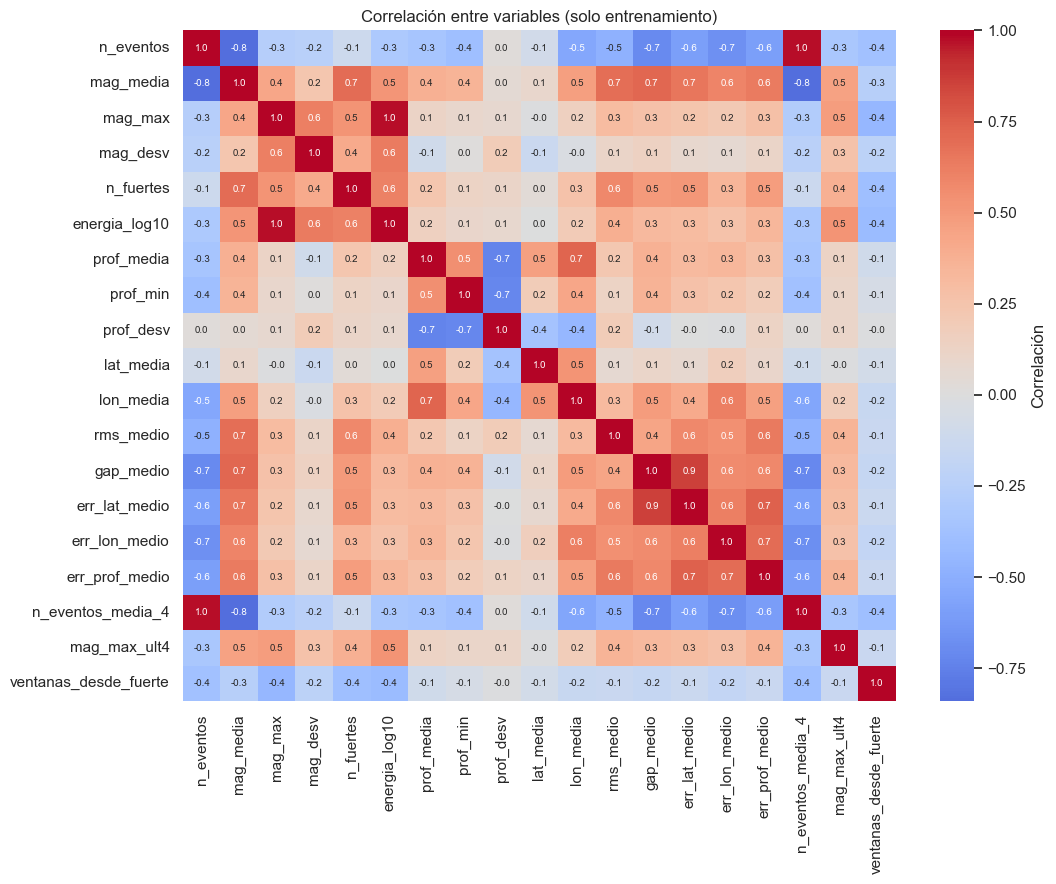

In [10]:
corr = X_train.corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 7}, cbar_kws={"label": "Correlación"})
plt.title("Correlación entre variables (solo entrenamiento)"); plt.tight_layout(); plt.show()

## Parte 9 · Los modelos (y contra quién se comparan)

Se prueban **cuatro opciones**, de la más simple a la más compleja, para ver si la complejidad vale la pena:

| Modelo | En palabras simples |
|---|---|
| **Siempre "normal"** (referencia) | Responde siempre la clase más común. Si un modelo no supera esto, no sirve. |
| **Persistencia** (referencia) | "Si esta semana tuvo actividad alta, la próxima también." Es la regla de sentido común. |
| **Regresión logística** | Una fórmula que pondera cada variable y da una probabilidad. Fácil de explicar. |
| **Random Forest** | Cientos de "árboles de decisión" que votan. Capta relaciones más complejas. |

**Desbalance de clases sin inventar datos:** las semanas de actividad alta son menos que las normales. En vez de crear semanas falsas (como hacía SMOTE), se le da **más peso** a los ejemplos reales de la clase menos frecuente (`class_weight="balanced"`).

**Cómo se elige el mejor:** con **validación cruzada temporal** dentro del entrenamiento (varias veces: entrena con un tramo del pasado y valida con el siguiente). Así se escoge el modelo **sin mirar la prueba**, y la prueba se usa una sola vez al final.

In [11]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

modelos = {
    "Regresión logística": make_pipeline(
        SimpleImputer(strategy="median", keep_empty_features=True), StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEMILLA)),
    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median", keep_empty_features=True),
        RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
                               random_state=SEMILLA, n_jobs=-1)),
}

# Validación cruzada temporal (solo con entrenamiento) para ELEGIR modelo
tscv = TimeSeriesSplit(n_splits=5)
cv_resultados = {}
for nombre, pipe in modelos.items():
    puntajes = cross_val_score(pipe, X_train, y_train, cv=tscv, scoring="roc_auc", error_score=np.nan)
    cv_resultados[nombre] = np.nanmean(puntajes) if np.isfinite(puntajes).any() else np.nan
    pipe.fit(X_train, y_train)

tabla_cv = pd.Series(cv_resultados, name="AUC en validación cruzada temporal (solo entrenamiento)").to_frame().round(3)
display(tabla_cv)
mejor_nombre = tabla_cv.iloc[:, 0].astype(float).idxmax() if tabla_cv.iloc[:, 0].notna().any() else "Random Forest"
mejor = modelos[mejor_nombre]
print(f"Modelo elegido (mejor AUC en validación cruzada): {mejor_nombre}")

,AUC en validación cruzada temporal (solo entrenamiento)
Regresión logística,0.640
Random Forest,0.616


Modelo elegido (mejor AUC en validación cruzada): Regresión logística


## Parte 10 · Resultados en el futuro (conjunto de prueba)

**Cómo leer las métricas** (todas van de 0 a 1; más alto es mejor):

- **Exactitud (accuracy):** de todas las semanas, ¿en cuántas acertó? Engaña cuando una clase es mucho más común, por eso se mira también la siguiente.
- **Exactitud balanceada:** el promedio de acierto en cada clase por separado. Más justa si hay desbalance.
- **Precisión:** cuando el modelo dice "actividad alta", ¿cuántas veces tiene razón? *(Bajo = muchas falsas alarmas.)*
- **Sensibilidad (recall):** de las semanas realmente de actividad alta, ¿cuántas detectó? *(Bajo = se le escapan.)*
- **F1:** resumen entre precisión y sensibilidad.
- **AUC:** qué tan bien ordena las semanas de menor a mayor riesgo. 0,5 = azar; 1 = perfecto.

**Matriz de confusión:** una tabla de aciertos y errores. La diagonal son aciertos; fuera de ella, errores (falsas alarmas y alertas perdidas).

,Exactitud,Exactitud balanceada,Precisión,Sensibilidad,F1,AUC
Siempre 'normal' (referencia),0.851,0.500,0.000,0.000,0.000,0.500
Persistencia (referencia),0.730,0.469,0.096,0.096,0.096,0.458
Regresión logística,0.362,0.506,0.152,0.712,0.250,0.512
Random Forest,0.851,0.500,0.000,0.000,0.000,0.485


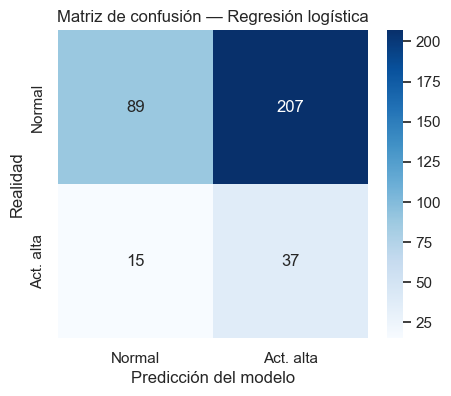


=== LECTURA HONESTA ===
El modelo supera a la persistencia (AUC 0.51 vs 0.46), pero con capacidad moderada. Úsalo como apoyo, no como decisión única.
Prueba con 348 ventanas, de las cuales 52 fueron de actividad alta. Con pocas ventanas, los resultados pueden variar mucho.


In [12]:
def metricas(y_real, y_pred, score):
    ok_auc = y_real.nunique() == 2
    return {"Exactitud": accuracy_score(y_real, y_pred),
            "Exactitud balanceada": balanced_accuracy_score(y_real, y_pred),
            "Precisión": precision_score(y_real, y_pred, zero_division=0),
            "Sensibilidad": recall_score(y_real, y_pred, zero_division=0),
            "F1": f1_score(y_real, y_pred, zero_division=0),
            "AUC": roc_auc_score(y_real, score) if ok_auc else np.nan}

filas = {}
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
filas["Siempre 'normal' (referencia)"] = metricas(y_test, dummy.predict(X_test), np.zeros(len(y_test)))

pers = (X_test["mag_max"].fillna(-np.inf) >= umbral).astype(int)
filas["Persistencia (referencia)"] = metricas(y_test, pers, X_test["mag_max"].fillna(X_test["mag_max"].min()))

for nombre, pipe in modelos.items():
    filas[nombre] = metricas(y_test, pipe.predict(X_test), pipe.predict_proba(X_test)[:, 1])

tabla_test = pd.DataFrame(filas).T.round(3)
display(tabla_test)

pred_mejor = mejor.predict(X_test)
cm = confusion_matrix(y_test, pred_mejor, labels=[0, 1])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Normal", "Act. alta"], yticklabels=["Normal", "Act. alta"])
plt.title(f"Matriz de confusión — {mejor_nombre}"); plt.ylabel("Realidad"); plt.xlabel("Predicción del modelo"); plt.show()

# Lectura automática del resultado (sin adornos)
auc_m = tabla_test.loc[mejor_nombre, "AUC"]; auc_p = tabla_test.loc["Persistencia (referencia)", "AUC"]
print("\n=== LECTURA HONESTA ===")
if np.isnan(auc_m):
    print("La prueba tiene una sola clase; no se puede calcular AUC. Revisa umbral/ventana.")
elif auc_m >= 0.7 and auc_m > auc_p + 0.02:
    print(f"El modelo ({mejor_nombre}) ordena las semanas mejor que la regla simple de persistencia (AUC {auc_m:.2f} vs {auc_p:.2f}). Hay señal útil, aunque no es una bola de cristal.")
elif auc_m > auc_p + 0.02:
    print(f"El modelo supera a la persistencia (AUC {auc_m:.2f} vs {auc_p:.2f}), pero con capacidad moderada. Úsalo como apoyo, no como decisión única.")
else:
    print(f"El modelo NO supera claramente a la regla simple (AUC {auc_m:.2f} vs {auc_p:.2f}). Con estos datos, la actividad reciente aporta poco para anticipar la semana siguiente.")
print(f"Prueba con {len(y_test)} ventanas, de las cuales {int(y_test.sum())} fueron de actividad alta. Con pocas ventanas, los resultados pueden variar mucho.")

## Parte 11 · ¿Qué variables pesaron más?

**Para qué sirve:** abrir la "caja negra". Se usa **importancia por permutación**: se barajan los valores de una variable y se mide cuánto empeora el modelo. Si empeora mucho, esa variable era importante; si no cambia nada, el modelo no la necesitaba.

**Cómo leerlo:** barras más largas = la variable aporta más a distinguir semanas de actividad alta. Barras cerca de cero (o negativas) = no aportan, y es normal que haya varias. Esto indica **asociación**, no causa.

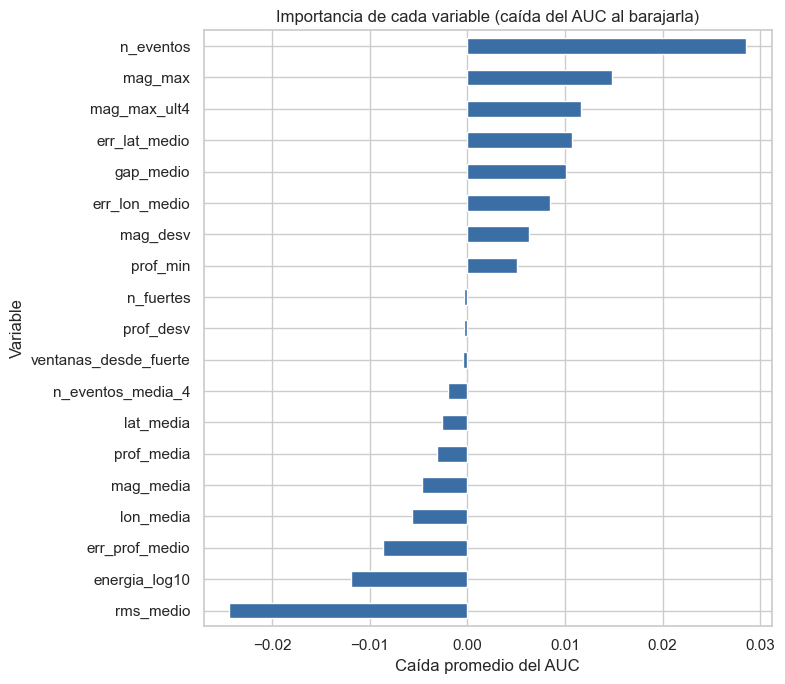

Las 5 más influyentes: n_eventos, mag_max, mag_max_ult4, err_lat_medio, gap_medio


In [13]:
from sklearn.inspection import permutation_importance

if y_test.nunique() == 2:
    imp = permutation_importance(mejor, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=SEMILLA, n_jobs=-1)
    imp_df = pd.DataFrame({"Variable": FEATURES, "Importancia": imp.importances_mean, "Variación": imp.importances_std}).sort_values("Importancia")
    imp_df.plot(kind="barh", x="Variable", y="Importancia", xerr=imp_df["Variación"], legend=False, figsize=(8, 7), color="#3b6ea5")
    plt.title("Importancia de cada variable (caída del AUC al barajarla)"); plt.xlabel("Caída promedio del AUC"); plt.tight_layout(); plt.show()
    print("Las 5 más influyentes:", ", ".join(imp_df.sort_values("Importancia", ascending=False)["Variable"].head(5)))
else:
    print("La prueba tiene una sola clase; no se calcula la importancia.")

## Parte 12 · Uso práctico con datos reales (sin valores inventados)

El MVP original pedía escribir a mano latitud, magnitud, etc., con valores de ejemplo sin origen en tus datos. Aquí se hace distinto: el modelo mira **las últimas semanas reales de tu catálogo** y reporta la probabilidad de actividad alta para la semana siguiente de cada una.

**Cómo leer la tabla:**
- **Prob. actividad alta (semana siguiente):** la estimación del modelo, de 0 % a 100 %.
- **Resultado real:** lo que realmente pasó (vacío si esa "semana siguiente" aún no está en los datos).
- **Conjunto:** si esa semana se usó para *entrenar* o para *probar*. Las probabilidades sobre semanas de entrenamiento son optimistas; las de prueba son las honestas.

Esto es una **herramienta de apoyo para análisis**, no un sistema de alerta temprana oficial. Las alertas reales las emiten el Servicio Geológico Colombiano y las autoridades de gestión del riesgo.

In [14]:
ultimas = completas.iloc[-8:].copy()
prob = mejor.predict_proba(ultimas[FEATURES])[:, 1]

def conjunto(idx):
    if idx in train.index: return "entrenamiento"
    if idx in test.index:  return "prueba"
    return "sin resultado aún"

vista = pd.DataFrame({
    "Inicio de la ventana": ultimas.index.date,
    "Sismos en la ventana": ultimas["n_eventos"].astype(int).values,
    "Magnitud máx.": ultimas["mag_max"].round(2).values,
    "Prob. actividad alta (semana siguiente)": (prob * 100).round(1).astype(str) + " %",
    "Resultado real": ["Actividad alta" if (i < len(ultimas) - 1 and (not np.isnan(m)) and m >= umbral)
                       else ("Normal" if i < len(ultimas) - 1 else "—")
                       for i, m in enumerate(ultimas["mag_max_siguiente"].values)],
    "Conjunto": [conjunto(i) for i in ultimas.index],
})
display(vista)

ult = ultimas.iloc[-1]
print(f"\nÚltima ventana completa que inicia el {ultimas.index[-1].date()}: "
      f"{int(ult['n_eventos'])} sismos, magnitud máxima {ult['mag_max']:.2f}.")
print(f"Probabilidad estimada de actividad alta (≥ {umbral:.2f}) en la ventana siguiente: {prob[-1]*100:.1f} %")
print(f"Para dar contexto: en entrenamiento, {y_train.mean()*100:.1f} % de las ventanas fueron de actividad alta.")

,Inicio de la ventana,Sismos en la ventana,Magnitud máx.,Prob. actividad alta (semana siguiente),Resultado real,Conjunto
0,2026-08-18,68,3.6,69.1 %,Actividad alta,prueba
1,2026-08-25,59,5.1,50.8 %,Normal,prueba
2,2026-09-01,71,4.1,51.0 %,Normal,prueba
3,2026-09-08,62,4.0,59.1 %,Normal,prueba
4,2026-09-15,59,3.4,51.9 %,Normal,prueba
5,2026-09-22,29,4.1,67.0 %,Normal,prueba
6,2026-09-29,45,3.9,63.0 %,Normal,prueba
7,2026-10-06,39,3.6,57.7 %,—,sin resultado aún



Última ventana completa que inicia el 2026-10-06: 39 sismos, magnitud máxima 3.60.
Probabilidad estimada de actividad alta (≥ 4.60) en la ventana siguiente: 57.7 %
Para dar contexto: en entrenamiento, 21.0 % de las ventanas fueron de actividad alta.


## Parte 13 · Guardar el modelo

Se guarda el modelo **junto con** su lista de variables, el umbral y la ventana de tiempo, para poder reutilizarlo después sin adivinar con qué configuración se entrenó.

In [15]:
import joblib
paquete = {"modelo": mejor, "nombre_modelo": mejor_nombre, "variables": FEATURES, "umbral_mag": umbral,
           "ventana": VENTANA, "mag_fuerte": MAG_FUERTE,
           "periodo_entrenamiento": (str(train.index.min().date()), str(train.index.max().date()))}
joblib.dump(paquete, RAIZ / "modelos/supervisado/modelo_riesgo_sismico_v2.pkl")
print("Guardado: modelo_riesgo_sismico_v2.pkl")

Guardado: modelo_riesgo_sismico_v2.pkl


## Parte 14 · Conclusiones y límites

**Lo que se corrigió:** fuga de información eliminada · cero datos sintéticos (adiós SMOTE) · duplicados y rangos inválidos tratados con cuentas claras · municipios solo si vienen en el archivo · hasta 20 variables definidas y documentadas · prueba en el futuro real · comparación contra reglas simples · resultados reproducibles de arriba abajo.

**Lo que este modelo NO hace:**
- **No predice cuándo ni dónde ocurrirá un sismo específico.** Nadie puede hoy.
- Estima si la actividad reciente se parece a la que antecedió a semanas intensas.
- Su calidad depende de cuántas semanas tenga tu catálogo y de que la red de sensores no haya cambiado a lo largo de los años.

**Ideas para seguir mejorando (sin inventar datos):**
1. Probar ventanas de 3 o 14 días y comparar.
2. Agregar variables por zona (por ejemplo, por cuadrícula geográfica) si el catálogo tiene suficientes sismos fuera del nido principal.
3. Repetir la evaluación con varios cortes temporales para ver qué tan estable es el resultado.
4. Si consigues datos reales de daños o percepción (por ejemplo, reportes ciudadanos), definir un riesgo basado en impacto y no solo en magnitud.